In [1]:
import os, glob, sys
sys.path.append("../")

import numpy as np
from matplotlib import pyplot as plt
from scipy.interpolate import griddata, RegularGridInterpolator
import pygeode as pyg
from jfunctions import *
import scipy.interpolate as intp
from scipy.ndimage import uniform_filter1d
import xarray as xr
from wavenumber_frequency_functions import *


%matplotlib widget

save = False
include_spinup = False

save_loc = '/home/cwp29/tmp/mpas/feb26/'

In [2]:
#spin_dir = '/data/phh1-hosted/cwp29/mpas-a/data/trop_ref/spinup/'
#data_dir = '/data/phh1-hosted/cwp29/mpas-a/data/trop_ref/spinup/'
spin_dir = '/store/atmos-adk33/cwp29/mpas-a/data/trop_ref/microp_re_test/'
data_dir = '/store/atmos-adk33/cwp29/mpas-a/data/trop_ref/microp_re_test/'

dsd = pyg.open(data_dir+'latlon.nc')
dsd_spinup = pyg.open(spin_dir+'latlon.nc')

ds_rrb120 = pyg.open('/store/ATMOS/cwp29/mpas-a/data/rrb/daily_fields_latlon_1deg_2yrs_120km_control.nc')
ds_rrb30 = pyg.open('/store/ATMOS/cwp29/mpas-a/data/rrb/daily_fields_latlon_1deg_2yrs_30km.nc')
ds_rrb15 = pyg.open('/store/ATMOS/cwp29/mpas-a/data/rrb/daily_fields_latlon_1deg_2yrs_15km.nc')

In [6]:
print(dsd)

<Dataset>:
Vars:
  u                    (Time,nVertLevels,latitude,longitude)  (240,75,900,1800)
  pressure             (Time,nVertLevels,latitude,longitude)  (240,75,900,1800)
  theta                (Time,nVertLevels,latitude,longitude)  (240,75,900,1800)
  uReconstructZonal    (Time,nVertLevels,latitude,longitude)  (240,75,900,1800)
  temperature_surface  (Time,latitude,longitude)              (240,900,1800)
  t_isobaric           (Time,nIsoLevelsT,latitude,longitude)  (240,22,900,1800)
  omg_isobaric         (Time,nIsoLevelsZ,latitude,longitude)  (240,22,900,1800)
  rh_isobaric          (Time,nIsoLevelsT,latitude,longitude)  (240,22,900,1800)
  qv_isobaric          (Time,nIsoLevelsT,latitude,longitude)  (240,22,900,1800)
  uzonal_isobaric      (Time,nIsoLevelsU,latitude,longitude)  (240,22,900,1800)
  umeridional_isobaric (Time,nIsoLevelsU,latitude,longitude)  (240,22,900,1800)
  olrtoa               (Time,latitude,longitude)              (240,900,1800)
  i_rainc              (Time,

ValueError: String "%s" not recognized as a time

In [4]:
ndays = 10.
dt = 6. # hours
idx_h = int(ndays * 24./dt)
idx_d = int(ndays)
idx_max_h = len(dsd.Time)
idx_max_d = int(np.ceil(len(dsd.Time)/int(24/dt)))

# Removed "idx_max_(d/h)_rrb" because it wasn't doing the right thing anymore.
# If want to plot the last ndays of data, this works.

print(idx_h, idx_d)
print(idx_max_h, idx_max_d)

40 10
240 60


[ 15.90420355  16.53198287  17.16123993  17.80025693  18.45288002
  19.10424009  19.75165197  20.43051328  21.09725855  21.72809858
  22.34970772  22.96426704  23.61465205  24.26864171  24.91822809
  25.58316048  26.26074179  26.90738567  27.53925002  28.17542462
  28.83392323  29.48380461  30.12204183  30.7847859   31.45579251
  32.09548885  32.7241526   33.37313703  34.02053495  34.65213217
  35.29179912  35.95790056  36.62023619  37.27309029  37.92884571
  38.60869202  39.28923766  39.97633184  40.69104023  41.42273206
  42.1510504   42.8923773   43.65358749  44.40984541  45.1648411
  45.93127811  46.70941285  47.49321263  48.27262158  49.05252105
  49.83575402  50.60192772  51.36020849  52.11197721  52.86444733
  53.62738139  54.38114159  55.13836716  55.88946763  56.64473465
  57.42556029  58.17249517  58.94693387  59.71606909  60.48265774
  61.26434163  62.05576565  62.84725713  63.63050672  64.40784616
  65.1955618   65.98616671  66.78902336  67.59767352  68.41822928
  69.241139

/alt/applic/user-maint/cwp29/Conda/envs/python/lib/python3.11/site-packages/numpy/core/_methods.py:49: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)


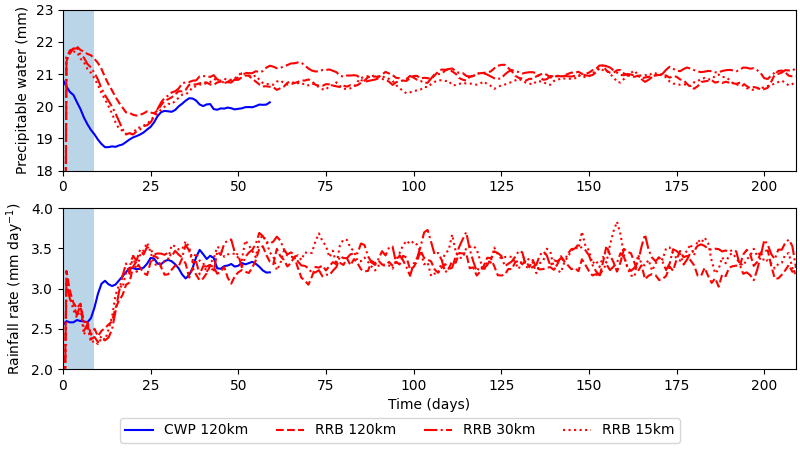

In [7]:
# rainc, rainnc contain accumulated rainfall from simulation start to given timestep
fig, ax = plt.subplots(2, 1, figsize=(8, 4.5), constrained_layout=True)

if include_spinup:
    precip_run = dsd.rainnc + dsd.i_rainnc*100. + dsd.rainc + dsd.i_rainnc*100.
    precip_spinup = dsd_spinup.rainnc + dsd_spinup.i_rainnc*100. + dsd_spinup.rainc + dsd_spinup.i_rainnc*100.
    
    precip_rate_run = np.gradient(precip_run.mean('lat', 'lon')[::int(24/dt)])
    precip_rate_spinup = np.gradient(precip_spinup.mean('lat', 'lon')[::int(24/dt)])
    
    precip_water_run = fix_time(dsd.precipw).mean('lat', 'lon').dailymean()[:]
    precip_water_spinup = fix_time(dsd_spinup.precipw).mean('lat', 'lon').dailymean()[:]

    precip_rate = np.concatenate((precip_rate_spinup, precip_rate_run))
    precip_water = np.concatenate((precip_water_spinup, precip_water_run))
else:
    precip = dsd.rainnc + dsd.i_rainnc*100. + dsd.rainc + dsd.i_rainnc*100.

    precip_rate = np.gradient(precip.mean('lat', 'lon')[::int(24/dt)])
    
    precip_water = dsd.precipw.mean('lat', 'lon')[::int(24/dt)]

print(precip.mean('lat', 'lon')[:])
ax[0].plot(precip_water, color='b', label='CWP 120km')
ax[1].plot(precip_rate, color='b')

style_dicts = [{'ls': '--', 'label':'RRB 120km'},
          {'ls': '-.', 'label':'RRB 30km'}, 
          {'ls':':', 'label':'RRB 15km'}
         ]
for ds, s in zip([ds_rrb120, ds_rrb30, ds_rrb15], style_dicts):
    ax[0].plot(ds.precipw.mean('lat', 'lon')[:], ls=s['ls'], color='r', label=s['label'])
    ax[1].plot(ds.pr.mean('lat', 'lon')[:], ls=s['ls'], color='r')

ax[0].fill_between(range(idx_d), 18, 23, alpha=0.3)
ax[1].fill_between(range(idx_d), 2, 4, alpha=0.3)

ax[0].set_ylim(18, 23)
ax[0].set_ylabel(r"Precipitable water (mm)")

ax[1].set_ylim(2, 4)
ax[1].set_ylabel(r"Rainfall rate (mm day$^{-1}$)")

ax[1].set_xlabel('Time (days)')

for a in ax:
    a.set_xlim(0, 209)

fig.legend(loc='outside lower center', ncol=4)

if save: save_fig(fig, save_loc+'comp_rain_stats.png', dpi=300)

In [ ]:
lats = dsd.latitude
lons = dsd.longitude

ubar = dsd.uzonal_isobaric(i_Time = (idx_max_h-idx_h, idx_max_h)).mean('longitude', 'Time')[:]
vbar = dsd.umeridional_isobaric(i_Time = (idx_max_h-idx_h, idx_max_h)).mean('longitude', 'Time')[:]
omgbar = dsd.omg_isobaric(i_Time = (idx_max_h-idx_h, idx_max_h)).mean('longitude', 'Time')[:]
rhbar = dsd.rh_isobaric(i_Time = (idx_max_h-idx_h, idx_max_h)).mean('longitude', 'Time')[:]
Tbar = dsd.t_isobaric(i_Time = (idx_max_h-idx_h, idx_max_h)).mean('longitude', 'Time')[:]

/alt/applic/user-maint/cwp29/Conda/envs/python/lib/python3.11/site-packages/pygeode/view.py:283: UserWarning: <Var 'uzonal_isobaric'> is supposed to return a float32, but is returning float64
  warn ("%s is supposed to return a %s, but is returning %s"%(repr(var),var.dtype.name,values.dtype.name))


In [ ]:
fig, ax = plt.subplots(4, 2, figsize=(8, 8), sharey=True, constrained_layout=True)

pres = np.array([100, 200, 300, 500, 700, 1000, 2000, 3000, 5000, 7000, 10000, 15000, 20000, 25000, 30000, 40000, 50000, 60000, 70000, 85000, 92500, 100000], dtype=np.float64)
pres /= 100

def plot_Tu_latpres(a, lats, pres, Tbar, ubar):
    T_im = a.contourf(lats, pres, Tbar, levels=np.arange(190, 305, 5), extend='both', cmap='coolwarm')
    u_im_neg = a.contour(lats, pres, ubar, levels=np.arange(-20, 0, 5), colors='k', linestyles=':', linewidths=0.5)
    u_im_zero = a.contour(lats, pres, ubar, levels=[0], colors='k', linewidths=1)
    u_im_pos = a.contour(lats, pres, ubar, levels=np.arange(5, 55, 5), colors='k', linewidths=0.5)
    a.clabel(u_im_pos, u_im_pos.levels, fontsize=6)
    a.clabel(u_im_neg, u_im_neg.levels, fontsize=6)

    return T_im, u_im_neg, u_im_zero, u_im_pos

def plot_rhv_latpres(a, lats, pres, rhbar, vbar, omgbar):
    xi = np.linspace(lats.min(), lats.max(), len(lats))
    yi = np.linspace(pres.min(), pres.max(), len(pres))

    X, Y = np.meshgrid(xi, yi)

    U = intp.interpn((lats, pres), vbar.T, (X, Y))
    V = intp.interpn((lats, pres), omgbar.T, (X, Y))

    rh_im = a.contourf(lats, pres, rhbar, levels=np.arange(0, 105, 5), cmap='BrBG')
    medcirc_im = a.streamplot(X, Y, U/111111., V/100., color='k', linewidth=1, density=1)

    return rh_im, medcirc_im

T_im, _, _, _ = plot_Tu_latpres(ax[0, 0], lats, pres, Tbar, ubar)
rh_im, _ = plot_rhv_latpres(ax[0, 1], lats, pres, rhbar, vbar, omgbar)

for r, ds in enumerate([ds_rrb120, ds_rrb30, ds_rrb15]):
    tbar_rrb = ds.ta(i_time = (-1-idx_d, -1)).mean('Time', 'lon')[:]
    ubar_rrb = ds.ua(i_time = (-1-idx_d, -1)).mean('Time', 'lon')[:]
    rhbar_rrb = ds.hur(i_time = (-1-idx_d, -1)).mean('Time', 'lon')[:]
    vbar_rrb = ds.va(i_time = (-1-idx_d, -1)).mean('Time', 'lon')[:]
    omgbar_rrb = ds.wap(i_time = (-1-idx_d, -1)).mean('Time', 'lon')[:]

    plot_Tu_latpres(ax[r+1, 0], ds.lat[:], ds.plev[:]/100, tbar_rrb.T, ubar_rrb.T)
    plot_rhv_latpres(ax[r+1, 1], ds.lat[:], ds.plev[:]/100, rhbar_rrb.T, vbar_rrb.T, omgbar_rrb.T)

#for i in range(ax.shape[0]-1):
    #ax[i, 0].set_xticklabels([])
    #ax[i, 1].set_xticklabels([])

ax[0, 0].set_xticklabels([])
ax[0, 1].set_xticklabels([])

ax[1, 0].set_xlabel("Latitude (degrees)")
ax[1, 1].set_xlabel("Latitude (degrees)")
    
for i in range(ax.shape[0]):
    ax[i, 0].set_ylabel("Pressure (hPa)")
    
ax[0, 0].invert_yaxis()
ax[0, 0].set_yscale('log')
    
for a in ax.ravel():
    a.set_xlim(-90, 90)
    a.set_ylim(1000, 10)
    
fig.colorbar(T_im, ax=ax[-1, 0], location='bottom', label="temperature (K)")
fig.colorbar(rh_im, ax=ax[-1, 1], location='bottom', label="relative humidity (%)")

if save: save_fig(fig, save_loc+'comp_temp_relhum.png', dpi=300)

In [ ]:
# Calculate meridional eddy fluxes

ua = dsd.uzonal_isobaric(i_Time = (idx_max_h-idx_h, idx_max_h), l_nIsoLevelsU=(13, 18))[:] - ubar[np.newaxis, np.array([13, 18]), :, np.newaxis]
va = dsd.umeridional_isobaric(i_Time = (idx_max_h-idx_h, idx_max_h), l_nIsoLevelsU=(13, 18))[:] - vbar[np.newaxis, np.array([13, 18]), :, np.newaxis]
Ta = dsd.t_isobaric(i_Time = (idx_max_h-idx_h, idx_max_h), l_nIsoLevelsT=(13, 18))[:] - Tbar[np.newaxis, np.array([13, 18]), :, np.newaxis]
qva = dsd.qv_isobaric(i_Time = (idx_max_h-idx_h, idx_max_h), l_nIsoLevelsT=(13, 18))[:] - dsd.qv_isobaric(i_Time = (idx_max_h - idx_h, idx_max_h), l_nIsoLevelsT=(13, 18)).mean('longitude', 'Time')[:][np.newaxis, :, :, np.newaxis]

eke = np.mean(ua*ua + va*va, axis=(0, 3))
memf = np.mean(ua*va, axis=(0, 3))
mehf = np.mean(va*Ta, axis=(0, 3))
mewvf = np.mean(va*qva, axis=(0, 3))

fig, ax = plt.subplots(4, 2, figsize=(8, 8), constrained_layout='True')

for i, var in enumerate([eke, memf, mehf, mewvf]):
    if i == 0:
        ax[i, 0].plot(lats, var[0], color='b', label="CWP 120km")
    else:
        ax[i, 0].plot(lats, var[0], color='b')
    ax[i, 1].plot(lats, var[1], color='b')

for a in ax.ravel():
    a.set_xlim(-90, 90)

#ax[0, 0].set_ylim(0, 350)
#ax[0, 1].set_ylim(0, 75)

ax[1, 0].set_ylim(-120, 120)
ax[1, 1].set_ylim(-14, 14)

lats_rrb = np.linspace(-90, 90, 180)

for r, ds in enumerate([ds_rrb120, ds_rrb30, ds_rrb15]):
    tbar_rrb = ds.ta(i_time = (-1-idx_d, -1)).mean('Time', 'lon')[:]
    ubar_rrb = ds.ua(i_time = (-1-idx_d, -1)).mean('Time', 'lon')[:]
    vbar_rrb = ds.va(i_time = (-1-idx_d, -1)).mean('Time', 'lon')[:]
    husbar_rrb = ds.hus(i_time = (-1-idx_d, -1)).mean('Time', 'lon')[:]

    ua = ds.ua(i_Time = (-1-idx_d, -1), l_plev=(25000, 70000))[:] - ubar_rrb[np.newaxis, :, np.newaxis, np.array([8, 13])]
    va = ds.va(i_Time = (-1-idx_d, -1), l_plev=(25000, 70000))[:] - vbar_rrb[np.newaxis, :, np.newaxis, np.array([8, 13])]
    Ta = ds.ta(i_Time = (-1-idx_d, -1), l_plev=(25000, 70000))[:] - tbar_rrb[np.newaxis, :, np.newaxis, np.array([8, 13])]
    qva = ds.hus(i_Time = (-1-idx_d, -1), l_plev=(25000, 70000))[:] - husbar_rrb[np.newaxis, :, np.newaxis, np.array([8, 13])]

    eke = 0.5*np.mean(ua*ua + va*va, axis=(0, 2))
    memf = np.mean(ua*va, axis=(0, 2))
    mehf = np.mean(va*Ta, axis=(0, 2))
    mewvf = np.mean(va*qva, axis=(0, 2))

    for i, var in enumerate([eke, memf, mehf, mewvf]):
        if i == 0:
            ax[i, 0].plot(lats_rrb, var[:, 0], ls=style_dicts[r]['ls'], label=style_dicts[r]['label'], color='r')
        else:
            ax[i, 0].plot(lats_rrb, var[:, 0], ls=style_dicts[r]['ls'], color='r')
            
        ax[i, 1].plot(lats_rrb, var[:, 1], ls=style_dicts[r]['ls'], color='r')

ax[0, 0].set_ylabel("Eddy kinetic \n energy (m$^2$ s$^{-2}$)")
ax[1, 0].set_ylabel("Meridional eddy \n momentum flux (m$^2$ s$^{-2}$)")
ax[2, 0].set_ylabel("Meridional heat \n flux (K m s$^{-1}$)")
ax[3, 0].set_ylabel("Meridional wv \n flux (g kg$^{-1}$ m s$^{-1}$)")

fig.legend(loc='outside lower center', ncol=4)
        
if save: save_fig(fig, save_loc+'comp_eddy_fluxes.png', dpi=300)

In [ ]:
#imerg_ds = xr.open_mfdataset(list(sorted(glob.glob('/store/ATMOS/cwp29/mpas-a/data/imerg/*3IMERG.*.nc4')))[:100], concat_dim='time', combine='nested')
imerg_ds = xr.open_mfdataset(list(sorted(glob.glob('/data/phh1-hosted/cwp29/imerg/*3IMERG.*.nc4')))[:100], concat_dim='time', combine='nested')

In [ ]:
imerg_pr = imerg_ds.precipitation.coarsen(lat=10).mean().coarsen(lon=10).mean()

In [ ]:
# Normalised rainfall intensity distribution
from scipy.ndimage import uniform_filter1d

fig, ax = plt.subplots(1, 3, figsize=(8, 3), constrained_layout=True, sharey=True)

h, bins = np.histogram(imerg_pr, bins=300, range=(0, 300))
h = uniform_filter1d(h, size=10)
ax[0].plot(0.5*(bins[1:] + bins[:-1]), h/h[0], color='k', ls=':', label='IMERG (Obs)')
ax[0].set_yscale('log')

precip_con = dsd.rainc + dsd.i_rainc*100.
precip_res = dsd.rainnc + dsd.i_rainnc*100.

for i, precip_var in enumerate([precip, precip_con, precip_res]):
    h, bins = np.histogram(np.gradient(precip_var[:][::8], axis=0), bins=300, range=(0, 300))
    h = uniform_filter1d(h, size=10)
    if i == 0:
        ax[i].plot(0.5*(bins[1:] + bins[:-1]), h/h[0], color='b', label='CWP 120km')
    else:
        ax[i].plot(0.5*(bins[1:] + bins[:-1]), h/h[0], color='b')
    ax[i].set_yscale('log')

for s, ds in enumerate([ds_rrb120, ds_rrb30, ds_rrb15]):
    for i, precip_var in enumerate([ds.pr[:], ds.prc[:], ds.pr[:]-ds.prc[:]]):
        h, bins = np.histogram(precip_var, bins=300, range=(0, 300))
        h = uniform_filter1d(h, size=10)
        if i == 0:
            ax[i].plot(0.5*(bins[1:] + bins[:-1]), h/h[0], color='r', ls=style_dicts[s]['ls'], label=style_dicts[s]['label'])
        else:
            ax[i].plot(0.5*(bins[1:] + bins[:-1]), h/h[0], color='r', ls=style_dicts[s]['ls'])
        ax[i].set_yscale('log')

# this is on 0.1deg grid!
#h, bins = np.histogram(imerg_ds.precipitation, bins=300, range=(0, 300))
#ax[0].plot(0.5*(bins[1:] + bins[:-1]), uniform_filter1d(h/h[0], size=10), color='k', label='IMERG')
#ax[0].set_yscale('log')

fig.legend(loc='outside lower center', ncol=5)

for a in ax:
    a.set_xlim(0, 300)
    a.set_ylim(1e-7, 1)
    a.set_xlabel("Rainfall rate (mm/h)")

ax[0].set_title("Total")
ax[0].set_ylabel("Normalised frequency")
ax[1].set_title("Parameterised")
ax[2].set_title("Resolved")
    
if save: save_fig(fig, save_loc+'comp_pr_dist.png', dpi=300)

In [ ]:
def calculate_rain_durations(pr_var, thresh):
    pr_thresh = np.where(pr_var > thresh, 1, 0)
    
    durations = []

    for i in range(pr_thresh.shape[1]):
        for j in range(pr_thresh.shape[2]):
            timeseries = pr_thresh[:, i, j]
    
            count = 0
            for k in range(pr_thresh.shape[0]):
                if timeseries[k] > 0:
                    count += 1
                else:
                    if count > 0:
                        durations.append(count)
                        count = 0
                        
    return durations
                    
fig, ax = plt.subplots(1, 3, figsize=(8, 3), constrained_layout=True, sharey=True)

h, bins = np.histogram(calculate_rain_durations(imerg_pr[-1-idx_d:-1], 5), bins=39, range=(1, 40))
h = uniform_filter1d(h, size=5)
ax[0].plot(0.5*(bins[1:] + bins[:-1]), h/h[0], color='k', ls=':', label='IMERG (Obs)')
ax[0].set_yscale('log')

for i, precip_var in enumerate([precip, precip_con, precip_res]):
    h, bins = np.histogram(calculate_rain_durations(np.gradient(precip_var[::8, :, :], axis=0)[-1-idx_d:-1], 5), bins=39, range=(1, 40))
    h = uniform_filter1d(h, size=5)
    if i == 0:
        ax[i].plot(0.5*(bins[1:] + bins[:-1]), h/h[0], color='b', label='CWP 120km')
    else:
        ax[i].plot(0.5*(bins[1:] + bins[:-1]), h/h[0], color='b')
    ax[i].set_yscale('log')
    
for s, ds in enumerate([ds_rrb120, ds_rrb30, ds_rrb15]):
    for i, precip_var in enumerate([ds.pr[:], ds.prc[:], ds.pr[:]-ds.prc[:]]):
        h, bins = np.histogram(calculate_rain_durations(precip_var[-1-idx_d:-1], 5), bins=39, range=(1, 40))
        h = uniform_filter1d(h, size=5)
        if i == 0:
            ax[i].plot(0.5*(bins[1:] + bins[:-1]), h/h[0], color='r', ls=style_dicts[s]['ls'], label=style_dicts[s]['label'])
        else:
            ax[i].plot(0.5*(bins[1:] + bins[:-1]), h/h[0], color='r', ls=style_dicts[s]['ls'])
        ax[i].set_yscale('log')

for a in ax:
    a.set_xlim(1, 60)
    a.set_xlabel("Duration (days)")
    
fig.legend(loc='outside lower center', ncol=5)

ax[0].set_title("Total")
ax[0].set_ylabel("Normalised frequency")
ax[1].set_title("Parameterised")
ax[2].set_title("Resolved")

if save: save_fig(fig, save_loc+'comp_duration_dist.png', dpi=300)

In [ ]:
data_locs = [
    data_dir + 'latlon.nc',
    '/store/ATMOS/cwp29/mpas-a/data/rrb/daily_fields_latlon_1deg_2yrs_120km_control.nc',
    '/store/ATMOS/cwp29/mpas-a/data/rrb/daily_fields_latlon_1deg_2yrs_30km.nc',
    '/store/ATMOS/cwp29/mpas-a/data/rrb/daily_fields_latlon_1deg_2yrs_15km.nc'
]

ndays_spinup = 60

#spec_levels = [0, 0.1, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0, 2.25, 2.5]
spec_levels = np.linspace(0, 2.5, 26)

fig, ax = plt.subplots(len(data_locs), 2, figsize=(8, 8), constrained_layout=True)

for d in range(len(data_locs)):
    dsx = xr.open_dataset(data_locs[d])

    if d > 0:
        pr = dsx.pr[ndays_spinup:]
    else:
        precip = dsx.rainc + dsx.i_rainc*100. + dsx.rainnc + dsx.i_rainnc*100.
        pr = precip.differentiate("Time", datetime_unit="D")
        pr = pr.rename({'latitude':'lat', 'longitude':'lon'})
        #pr = np.gradient(precip, dsx.Time/4., axis=0)[ndays_spinup:]

    if d == 0:
        spd = 4
    else:
        spd = 1
        
    raw_spectrum = spacetime_power(pr, lataggreg='mean', latitude_bounds=(-10, 10), dosymmetries=True, 
                                   segsize=int(96/spd), noverlap=int(60/spd), spd=spd)

    sym_smooth_spectrum = smooth_wavefreq(raw_spectrum.sel(component='symmetric'), freq_ax = 1)
    asym_smooth_spectrum = smooth_wavefreq(raw_spectrum.sel(component='antisymmetric'), freq_ax = 1)
    
    sym_sig_spectrum = raw_spectrum.sel(component='symmetric')/sym_smooth_spectrum
    asym_sig_spectrum = raw_spectrum.sel(component='antisymmetric')/asym_smooth_spectrum

    wn = sym_sig_spectrum.wavenumber
    f = sym_sig_spectrum.frequency

    sym_spec_im = ax[d, 0].contourf(wn, f, sym_sig_spectrum.T, levels=spec_levels, cmap='YlGnBu', extend='max')
    
    asym_spec_im = ax[d, 1].contourf(wn, f, asym_sig_spectrum.T, levels=spec_levels, cmap='YlGnBu', extend='max')
    
    freq, wavenum = genDispersionCurves()
    
    labels = ['MRG', 'IG', 'EIG', 'Kelvin', 'ER', 'IG']

    cols = [0.3, 0.5, 0.8]
    for i in range(3):
        for j in range(3):
            ax[d, 1].plot(wavenum[i, j], freq[i, j], color='r', alpha=0.5)
            ax[d, 0].plot(wavenum[i+3, j], freq[i+3, j], color='r', alpha=0.5)
    
    # Decorations
    for a in ax[d]:
        a.set_xlim(-15, 15)
        a.set_ylim(0, 0.5)
        
        if d == len(data_locs)-1:
            a.set_xlabel('Zonal wavenumber')
        else:
            a.set_xticklabels([])

    ax[d, 0].set_ylabel('Frequency (day$^{-1}$)')
    ax[d, 1].set_yticklabels([])
    
    ax[d, 0].axvline(0, color='k', ls='--')
    ax[d, 1].axvline(0, color='k', ls='--')

    if d == 0:
        ax[d, 0].annotate('ER', (-11, 0.12), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
        ax[d, 0].annotate('Kelvin', (10, 0.4), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
        ax[d, 0].annotate('IG', (-5, 0.4), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
        
        ax[d, 1].annotate('MRG', (-12, 0.07), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
        ax[d, 1].annotate('IG', (-5, 0.43), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
        ax[d, 1].annotate('EIG', (11, 0.32), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))

ax[0, 0].set_title('Symmetric')
ax[0, 1].set_title('Anti-symmetric')

fig.colorbar(sym_spec_im, ax=ax[-1] ,location='bottom', shrink=0.5, label="Normalised power")

if save: save_fig(fig, save_loc+'comp_spectra.png', dpi=300)

In [ ]:
import matplotlib

precip_cols = [
    [255/255., 255/255., 255/255.], # white 
    [205/255., 236/255., 251/255.], # light blue 
    [157/255., 218/255., 247/255.], # blue
    [72/255., 142/255., 202/255.], # dark blue
    [72/255., 158/255., 148/255.], # light green
    [73/255., 181/255., 70/255.], # green
    [150/255., 203/255., 80/255.], # green-yellow
    [250/255., 232/255., 92/255.], # yellow
    [248/255., 184/255., 73/255.], # dark yellow
    [245/255., 106/255., 41/255.], # orange
    [230/255., 74/255., 41/255.], # dark orange
    [211/255., 31/255., 40/255.], # red
    [183/255., 27/255., 34/255.], # darker red
    [146/255., 21/255., 25/255.], #dark red
    [110/255., 15/255., 15/255.], #dark red
]
print(precip_cols)
precip_cmap = matplotlib.colors.LinearSegmentedColormap.from_list(name = "precip_rate", colors=precip_cols, N=len(precip_cols))

levels = np.linspace(0.01, 25, len(precip_cols))#[0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 3.0, 5.0, 7.5, 10.0, 15.0, 20.0, 25.0, 30.0, 35.0]

assert len(levels) == len(precip_cols)

precip_norm = matplotlib.colors.BoundaryNorm(boundaries=levels, ncolors=len(precip_cols)-1)

In [ ]:
# Hovmoller diagrams of daily precipitation rate
ndays = 60
precip = dsd.rainnc + dsd.i_rainnc*100. + dsd.rainc + dsd.i_rainnc*100.

lat_min = get_index(-10, precip.latitude[:])
lat_max = get_index(10, precip.latitude[:])

precip_rate_10avg = np.mean(np.gradient(precip[::4], axis=0)[:, lat_min:lat_max, :], axis=1)[-ndays:]

fig, ax = plt.subplots(1, 4, figsize=(8, 3), constrained_layout=True)

hovmoller_im = ax[0].contourf(precip.longitude, np.arange(ndays), precip_rate_10avg, levels=levels, norm=precip_norm, cmap=precip_cmap, extend='max')

ax[0].set_ylabel("time (days)")

fig.colorbar(hovmoller_im, ax=ax[-1], location='right', label="Precipitation rate (mm/h)")

for a in ax:
    a.set_xlabel("Longitude")

for i, ds in enumerate([ds_rrb120, ds_rrb30, ds_rrb15]):
    precip_rate_10avg = ds.pr(i_time=(-1-ndays, -1), lat=(-10, 10)).mean('lat')[:]
    ax[i+1].contourf(ds.lon[:], np.arange(ndays), precip_rate_10avg, levels=levels, norm=precip_norm, cmap=precip_cmap, extend='max')
    
if save: save_fig(fig, save_loc+'comp_hovmoller.png', dpi=300)